# Lab 2 · Fine-tune a pretrained ResNet18 + mini project: transfer learning for flower classification

**Course lab:** `CV-Week3-Lecture2.ipynb` (copy in `course-files/labs/`). Exercise: *"Fine-tune ResNet on custom dataset"* (freeze everything, replace `fc`). Mini project: *"Transfer learning for flower classification"*.

**What you will learn**
- How to organise your own images so `datasets.ImageFolder` can read them (`custom_data/train/<class>/…`, `custom_data/test/<class>/…`).
- Why pretrained models need **ImageNet normalisation** and 224×224 inputs.
- **Transfer learning:** load an ImageNet-trained ResNet18, **freeze** it (`requires_grad = False`), **replace the last layer `fc`**, and train only that layer.
- Proof that it works: the same ResNet18 **trained from scratch** on the same 500 flower photos does far worse.
- Proper evaluation: `model.eval()`, per-class accuracy, confusion matrix, correctly coloured prediction grid (the course's `imshow` shows wrong colours; we fix it).

**Run time.** 23 minutes on the 4-core CPU this notebook was built on, which was shared with other heavy jobs at the time (measured: see the last code cell). Most of it is the from-scratch comparison. An idle machine will be faster. On a Colab GPU it should take only a few minutes (estimate).

## 0 · Theory in 60 seconds

Full theory: [notes/03_modern_cnns_resnet_efficientnet.md](../notes/03_modern_cnns_resnet_efficientnet.md) and the notebook [03_modern_cnns_resnet_efficientnet.ipynb](../notebooks/03_modern_cnns_resnet_efficientnet.ipynb).

- **ResNet (2015):** residual blocks compute `out = F(x) + x`. The skip connection gives gradients a direct path back, so networks of 18, 50 or 152 layers train well. **ResNet18** = a 7×7 conv stem, 4 stages of 2 residual blocks each (64 → 128 → 256 → 512 channels), global average pool, then **`fc` = Linear(512 → 1000)**.
- **EfficientNet (2019):** scales depth, width and image resolution *together* (compound scaling) for the best accuracy per FLOP.
- **Transfer learning:** a network trained on ImageNet (1.28 million photos, 1000 classes) has already learned edges → textures → parts → objects. Those features are useful for *other* image tasks. We keep them and only learn a new final layer for our classes. This needs **little data and little compute**.

In [1]:
%matplotlib inline
import os, time, copy, random, shutil, tarfile, urllib.request

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
from torchvision import datasets
import torchvision.models as models

# While this notebook was built, other jobs shared the same 4-core CPU, so we limit PyTorch to 2 threads.
# On your own computer you can delete this line: PyTorch then uses all your cores.
torch.set_num_threads(2)
NOTEBOOK_START = time.time()
torch.manual_seed(0)
random.seed(0)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("torch", torch.__version__, "| torchvision", torchvision.__version__, "| device:", device)

torch 2.14.1+cu130 | torchvision 0.29.1+cu130 | device: cpu


## 1 · The custom dataset: building `custom_data/` for `ImageFolder`

The course writes `data_dir = './custom_data'` with the comment *"replace with your dataset folder"*, but doesn't provide one. **`datasets.ImageFolder` needs exactly this layout**: one sub-folder per class, and the folder name *is* the label:

```
custom_data/
├── train/
│   ├── daisy/       img001.jpg, img002.jpg, ...
│   ├── dandelion/   ...
│   └── ...
└── test/
    ├── daisy/       ...
    └── ...
```

For the mini project we use the **TensorFlow "flower_photos" dataset**: 3,670 photos of 5 flower types (daisy, dandelion, roses, sunflowers, tulips), from Flickr, under a Creative Commons licence (attributions in its `LICENSE.txt`). It is a 218 MB download from Google's storage server, reachable both here and on a normal connection.

**Small on purpose.** Transfer learning shines when you have *few* labelled images, so we use **100 training + 50 test photos per class** (500 + 250), picked at random with a fixed seed. Increase `N_TRAIN_PER_CLASS` to use more. Everything goes into `data/` (git-ignored), so `data_dir = './data/custom_data'`.

In [2]:
N_TRAIN_PER_CLASS = 100
N_TEST_PER_CLASS = 50
URL = "https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz"

os.makedirs("data", exist_ok=True)
if not os.path.isdir("data/flower_photos"):
    t = time.time()
    urllib.request.urlretrieve(URL, "data/flower_photos.tgz")
    with tarfile.open("data/flower_photos.tgz") as tar:
        if hasattr(tarfile, "data_filter"):
            tar.extractall("data", filter="data")     # safe extraction (Python 3.12+)
        else:
            tar.extractall("data")
    os.remove("data/flower_photos.tgz")
    print(f"downloaded and extracted in {time.time() - t:.0f}s")

flower_classes = sorted(d for d in os.listdir("data/flower_photos") if os.path.isdir(f"data/flower_photos/{d}"))
print("all photos:", {c: len(os.listdir(f"data/flower_photos/{c}")) for c in flower_classes})

# Build data/custom_data/{train,test}/<class>/ with a random (seeded) subset
data_dir = './data/custom_data'
shutil.rmtree(data_dir, ignore_errors=True)
rng = random.Random(0)
for c in flower_classes:
    files = sorted(os.listdir(f"data/flower_photos/{c}"))
    rng.shuffle(files)
    for split, chosen in [("train", files[:N_TRAIN_PER_CLASS]),
                          ("test", files[N_TRAIN_PER_CLASS:N_TRAIN_PER_CLASS + N_TEST_PER_CLASS])]:
        os.makedirs(f"{data_dir}/{split}/{c}", exist_ok=True)
        for f in chosen:
            shutil.copy(f"data/flower_photos/{c}/{f}", f"{data_dir}/{split}/{c}/{f}")
for split in ["train", "test"]:
    print(f"{data_dir}/{split}:", {c: len(os.listdir(f'{data_dir}/{split}/{c}')) for c in flower_classes})

downloaded and extracted in 6s
all photos: {'daisy': 633, 'dandelion': 898, 'roses': 641, 'sunflowers': 699, 'tulips': 799}


./data/custom_data/train: {'daisy': 100, 'dandelion': 100, 'roses': 100, 'sunflowers': 100, 'tulips': 100}
./data/custom_data/test: {'daisy': 50, 'dandelion': 50, 'roses': 50, 'sunflowers': 50, 'tulips': 50}


### The course's loader cell, explained

| Line | Why |
|---|---|
| `transforms.Resize((224,224))` | ResNet18 was trained on 224×224 crops. Our photos come in many sizes (e.g. 320×240, 500×333) and a batch needs equal sizes. `(224,224)` squashes to a square, ignoring the aspect ratio, which is simple and fine here. |
| `transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])` | the **mean and std of the ImageNet training images**, per channel (R, G, B). A pretrained network expects inputs normalised **exactly as during its training**, otherwise its features are off. |
| `datasets.ImageFolder(root=..., transform=...)` | scans the folders. Class names = sorted folder names, labels = 0, 1, 2… in that order. Each item = (transformed image, label). |
| `batch_size=32` | 32 images per weight update (smaller than Lab 1's 64 because 224×224 images use 49× more memory than 32×32) |

In [3]:
transform = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

trainset = datasets.ImageFolder(root=data_dir+'/train', transform=transform)
trainloader = torch.utils.data.DataLoader(trainset, batch_size=32, shuffle=True)

testset = datasets.ImageFolder(root=data_dir+'/test', transform=transform)
testloader = torch.utils.data.DataLoader(testset, batch_size=32, shuffle=False)

class_names = trainset.classes
print("Classes:", class_names)
print("class_to_idx:", trainset.class_to_idx)
print(f"train: {len(trainset)} images in {len(trainloader)} batches | test: {len(testset)} images")
print("first sample:", trainset.samples[0])

Classes: ['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips']
class_to_idx: {'daisy': 0, 'dandelion': 1, 'roses': 2, 'sunflowers': 3, 'tulips': 4}
train: 500 images in 16 batches | test: 250 images
first sample: ('./data/custom_data/train/daisy/102841525_bd6628ae3c.jpg', 0)


### Looking at the images: the course's `imshow` shows the wrong colours

The course's `imshow` does `img / 2 + 0.5`. That undoes `Normalize((0.5,),(0.5,))` from Lab 1, **but this lab normalised with the ImageNet mean/std** (std ≈ 0.23, so the normalised values run from about −2.1 to +2.6). To undo *that* you must compute `img * std + mean` per channel. With the course's formula the values are stretched too far and many fall outside 0…1, so matplotlib clips them: too much contrast, blown-out highlights, black shadows and shifted colours. Left: course version. Right: fixed (the true photo).

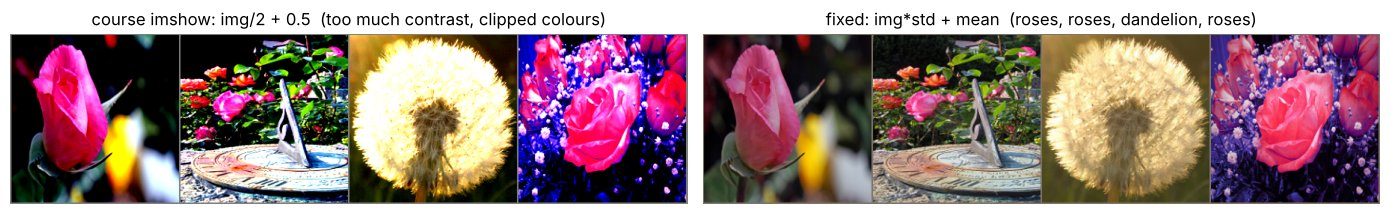

In [4]:
MEAN = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
STD = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

def imshow_course(img):            # the course's version (wrong for ImageNet normalisation)
    img = img / 2 + 0.5
    npimg = img.numpy()
    plt.imshow(np.clip(np.transpose(npimg, (1, 2, 0)), 0, 1))   # clip only so matplotlib doesn't warn

def imshow(img):                   # fixed: undo exactly the Normalize we applied
    img = img * STD + MEAN
    plt.imshow(np.clip(img.permute(1, 2, 0).numpy(), 0, 1))

images, labels = next(iter(torch.utils.data.DataLoader(trainset, batch_size=4, shuffle=True, generator=torch.Generator().manual_seed(3))))
grid = torchvision.utils.make_grid(images[:4])
plt.figure(figsize=(14, 4))
plt.subplot(1, 2, 1); imshow_course(grid); plt.axis("off"); plt.title("course imshow: img/2 + 0.5  (too much contrast, clipped colours)")
plt.subplot(1, 2, 2); imshow(grid); plt.axis("off"); plt.title("fixed: img*std + mean  (" + ", ".join(class_names[l] for l in labels) + ")")
plt.tight_layout(); plt.show()

## 2 · Exercise: fine-tune ResNet18 on the custom dataset

### 2.1 Loading pretrained weights: official route and fallback

The course writes `models.resnet18(pretrained=True)`. In torchvision ≥ 0.13 that is **deprecated**. The modern way is

```python
resnet18 = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)   # or .DEFAULT
```

The `weights` enum also records the preprocessing and the 1000 class names (`ResNet18_Weights.IMAGENET1K_V1.meta["categories"]`), so it is self-documenting.

The weights file comes from `download.pytorch.org`. That works on a normal connection, but **the machine this notebook was built on cannot reach it**. Fallback: the **same ResNet18 architecture with ImageNet weights published by the `timm` library on GitHub** (`resnet18.a1_in1k` from the "ResNet strikes back" paper, 2021). These weights use torchvision's exact layer names, so `load_state_dict` loads them into `models.resnet18()` with every key matching. The only difference is the training recipe used to produce them (torchvision lists 69.8 % ImageNet top-1 accuracy for its official weights; the timm weights are of similar quality). For our purposes both are "a ResNet18 that has already learned from ImageNet". The cell prints which route ran.

In [5]:
FALLBACK_URL = "https://github.com/rwightman/pytorch-image-models/releases/download/v0.1-rsb-weights/resnet18_a1_0-d63eafa0.pth"

def load_pretrained_resnet18():
    try:
        model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
        print("WEIGHTS ROUTE: official torchvision ResNet18_Weights.IMAGENET1K_V1")
    except Exception as e:
        print("Official weights download failed:", type(e).__name__, str(e)[:80])
        model = models.resnet18(weights=None)                             # same architecture, random weights...
        state = torch.hub.load_state_dict_from_url(FALLBACK_URL, model_dir="data/weights", map_location="cpu", progress=False)
        print("load_state_dict:", model.load_state_dict(state))           # ...then fill in ImageNet weights
        print("WEIGHTS ROUTE: fallback = timm resnet18.a1_in1k ImageNet weights from GitHub")
    return model

resnet18 = load_pretrained_resnet18()
print("original last layer:", resnet18.fc)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth
Official weights download failed: URLError <urlopen error Tunnel connection failed: 403 Forbidden>


Downloading: "https://github.com/rwightman/pytorch-image-models/releases/download/v0.1-rsb-weights/resnet18_a1_0-d63eafa0.pth" to data/weights/resnet18_a1_0-d63eafa0.pth


load_state_dict: <All keys matched successfully>
WEIGHTS ROUTE: fallback = timm resnet18.a1_in1k ImageNet weights from GitHub
original last layer: Linear(in_features=512, out_features=1000, bias=True)


**Sanity check: are these really ImageNet weights?** ImageNet's 1000 classes include **"daisy"**, but none of our other four flowers. So before we change anything, the untouched pretrained network should recognise the daisy, and for the other flowers pick the nearest thing it knows.

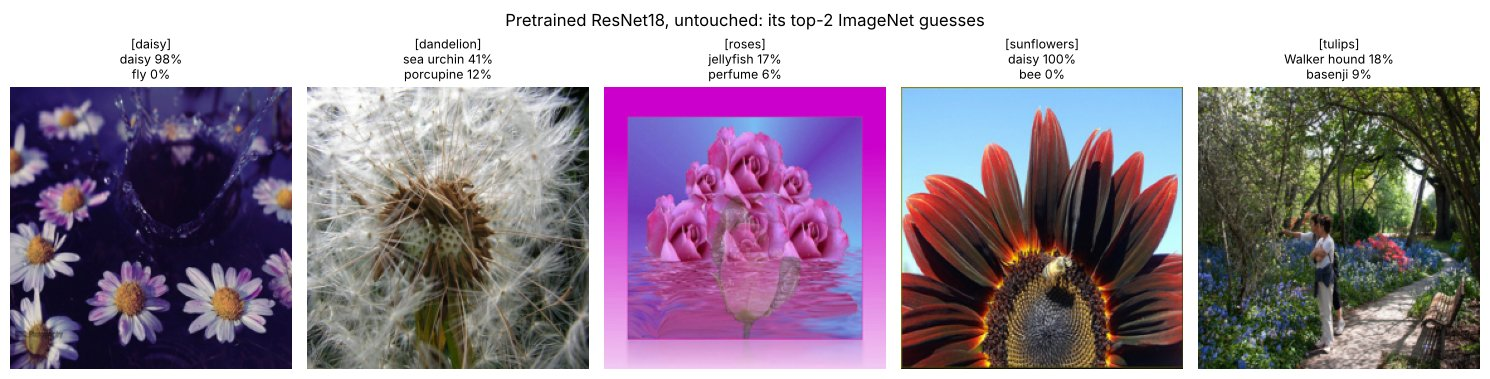

In [6]:
imagenet_classes = models.ResNet18_Weights.IMAGENET1K_V1.meta["categories"]     # the names ship with torchvision, no download
resnet18.eval()
plt.figure(figsize=(15, 3.6))
for k, c in enumerate(class_names):
    img_t, _ = testset[testset.targets.index(k)]                  # first test photo of each class
    with torch.no_grad():
        p = torch.softmax(resnet18(img_t.unsqueeze(0).to(device)), 1)[0].cpu()
    top = p.topk(2)
    plt.subplot(1, 5, k + 1); imshow(img_t); plt.axis("off")
    plt.title(f"[{c}]\n" + "\n".join(f"{imagenet_classes[i]} {v:.0%}" for v, i in zip(top.values, top.indices)), fontsize=9)
plt.suptitle("Pretrained ResNet18, untouched: its top-2 ImageNet guesses", y=1.04); plt.tight_layout(); plt.show()

### 2.2 Freeze, replace `fc`, train: the course's code, line by line

| Course line | Meaning |
|---|---|
| `for param in resnet18.parameters(): param.requires_grad = False` | **freeze**: PyTorch will not compute gradients for these weights, so the optimiser can't change them. (The course comment says "freeze early layers", but this loop freezes **all** layers.) |
| `num_ftrs = resnet18.fc.in_features` | the old last layer is `Linear(512 → 1000)`, so `num_ftrs = 512` |
| `resnet18.fc = nn.Linear(num_ftrs, len(class_names))` | a **brand-new** layer `Linear(512 → 5)`. New layers are created with `requires_grad=True`, so this is the **only trainable part**. |
| `optim.Adam(resnet18.fc.parameters(), lr=0.001)` | give the optimiser only the new layer's weights |

So the frozen ResNet acts as a fixed **feature extractor** (every image → 512 numbers) and we train a tiny classifier on top. This is the cheapest kind of transfer learning; "fine-tuning" usually means also unfreezing some layers later (see *Try this yourself*).

In [7]:
# Freeze early layers  (note: this loop freezes ALL layers)
for param in resnet18.parameters():
    param.requires_grad = False

# Replace final layer for custom classes
num_ftrs = resnet18.fc.in_features
resnet18.fc = nn.Linear(num_ftrs, len(class_names))

resnet18.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(resnet18.fc.parameters(), lr=0.001)

n_total = sum(p.numel() for p in resnet18.parameters())
n_train = sum(p.numel() for p in resnet18.parameters() if p.requires_grad)
print("new last layer:", resnet18.fc, "| num_ftrs =", num_ftrs)
print(f"trainable parameters: {n_train:,} of {n_total:,} ({100 * n_train / n_total:.3f}%)  = 512*5 weights + 5 biases")

new last layer: Linear(in_features=512, out_features=5, bias=True) | num_ftrs = 512
trainable parameters: 2,565 of 11,179,077 (0.023%)  = 512*5 weights + 5 biases


We wrap the course's training loop and its test loop in two small functions so that we can reuse them for the from-scratch model later. Changes from the course: we record losses and timings, and `evaluate` calls **`model.eval()`**, which the course forgets. The loop body is exactly the course's. The course trains `range(1, 3)` = 2 epochs; we train **6**, so we can see the curve level off (and give the from-scratch model the same budget).

In [8]:
def train_one_epoch(model, optimizer, loader):
    model.train()
    running_loss = 0.0
    for inputs, labels in loader:                       # ---- course loop body ----
        inputs, labels = inputs.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item()
    return running_loss / len(loader)

def evaluate(model, loader):
    model.eval()                                        # <- missing in the course
    correct, total, preds, trues = 0, 0, [], []
    with torch.no_grad():
        for inputs, labels in loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
            preds.append(predicted.cpu()); trues.append(labels.cpu())
    return 100 * correct / total, torch.cat(preds).numpy(), torch.cat(trues).numpy()

def fit(model, optimizer, epochs, name):
    hist = {"loss": [], "acc": [], "time": []}
    for epoch in range(1, epochs + 1):
        t = time.time()
        loss = train_one_epoch(model, optimizer, trainloader)
        hist["time"].append(time.time() - t)
        acc, _, _ = evaluate(model, testloader)
        hist["loss"].append(loss); hist["acc"].append(acc)
        print(f"[{name}] Epoch {epoch}, Loss: {loss:.4f}, test accuracy: {acc:.1f}%  (train time {hist['time'][-1]:.0f}s)")
    return hist

EPOCHS = 6
bn_before = resnet18.bn1.running_mean.clone()
hist_tl = fit(resnet18, optimizer, EPOCHS, "transfer")

[transfer] Epoch 1, Loss: 1.5400, test accuracy: 52.8%  (train time 76s)


[transfer] Epoch 2, Loss: 1.3628, test accuracy: 75.6%  (train time 69s)


[transfer] Epoch 3, Loss: 1.2202, test accuracy: 76.8%  (train time 41s)


[transfer] Epoch 4, Loss: 1.0976, test accuracy: 80.0%  (train time 57s)


[transfer] Epoch 5, Loss: 1.0111, test accuracy: 80.8%  (train time 42s)


[transfer] Epoch 6, Loss: 0.9193, test accuracy: 80.8%  (train time 28s)


**A subtle point about "frozen" BatchNorm.** `requires_grad = False` stops the *weights* from changing. But ResNet's BatchNorm layers also keep **running averages** of the data they see, and those are updated in `model.train()` mode **whether or not gradients are on**. So during training the "frozen" network still adapts its BatchNorm statistics a little to the flower photos:

In [9]:
print("bn1.weight.requires_grad:", resnet18.bn1.weight.requires_grad)
print(f"bn1.running_mean changed during training? {not torch.allclose(bn_before, resnet18.bn1.running_mean.cpu())}  "
      f"(largest change {(bn_before - resnet18.bn1.running_mean.cpu()).abs().max():.4f})")
print("To freeze it completely, put the backbone in eval mode while training: resnet18.train(); resnet18.apply(lambda m: m.eval() if isinstance(m, nn.BatchNorm2d) else None)")

bn1.weight.requires_grad: False
bn1.running_mean changed during training? True  (largest change 5.3415)
To freeze it completely, put the backbone in eval mode while training: resnet18.train(); resnet18.apply(lambda m: m.eval() if isinstance(m, nn.BatchNorm2d) else None)


## 3 · Mini project: transfer learning for flower classification

### 3.1 How good is it? Accuracy, per class, confusion matrix

Accuracy on test set: 80.80%  (202/250)

per-class accuracy (transfer learning):
  daisy        84.0%
  dandelion    78.0%
  roses        74.0%
  sunflowers   88.0%
  tulips       80.0%


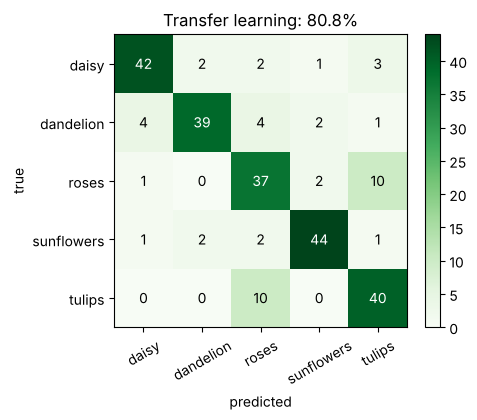

In [10]:
acc_tl, pred_tl, true = evaluate(resnet18, testloader)
print(f"Accuracy on test set: {acc_tl:.2f}%  ({(pred_tl == true).sum()}/{len(true)})\n")

def per_class_and_confusion(pred, true, title):
    k = len(class_names)
    cm = np.zeros((k, k), dtype=int)
    for t, p in zip(true, pred):
        cm[t, p] += 1
    for i, c in enumerate(class_names):
        print(f"  {c:11s} {100 * cm[i, i] / cm[i].sum():5.1f}%")
    plt.figure(figsize=(5, 4.3))
    plt.imshow(cm, cmap="Greens")
    for i in range(k):
        for j in range(k):
            plt.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black")
    plt.xticks(range(k), class_names, rotation=30); plt.yticks(range(k), class_names)
    plt.xlabel("predicted"); plt.ylabel("true"); plt.title(title); plt.colorbar(fraction=0.046)
    plt.tight_layout(); plt.show()

print("per-class accuracy (transfer learning):")
per_class_and_confusion(pred_tl, true, f"Transfer learning: {acc_tl:.1f}%")

### 3.2 Forgetting `model.eval()`: what the course's test loop would do

The course's test loop runs right after training, so the model is still in **training mode**. ResNet18 has no dropout, but it has **BatchNorm**: in training mode BatchNorm normalises with the statistics of the current test batch, so a prediction depends on which *other* images share the batch. It also overwrites the stored running averages with test data.

`ImageFolder` lists the test images class by class and the test loader doesn't shuffle, so each batch of 32 holds mostly one kind of flower. Normalising such a batch by its own average largely removes what the images have in common, i.e. the class, so the damage is extra large. We also measure it with shuffled batches.

In [11]:
m = copy.deepcopy(resnet18)
m.train()                                      # the state the course leaves the model in
correct = 0
with torch.no_grad():
    for inputs, labels in testloader:
        correct += (m(inputs.to(device)).argmax(1).cpu() == labels).sum().item()
print(f"test accuracy WITH model.eval():    {acc_tl:.2f}%")
print(f"test accuracy WITHOUT model.eval(): {100 * correct / len(testset):.2f}%  (BatchNorm used test-batch statistics)")

m = copy.deepcopy(resnet18); m.train()
shuffled = torch.utils.data.DataLoader(testset, batch_size=32, shuffle=True, generator=torch.Generator().manual_seed(0))
with torch.no_grad():
    correct = sum((m(x.to(device)).argmax(1).cpu() == y).sum().item() for x, y in shuffled)
print(f"WITHOUT model.eval(), shuffled test batches: {100 * correct / len(testset):.2f}%")

test accuracy WITH model.eval():    80.80%
test accuracy WITHOUT model.eval(): 47.20%  (BatchNorm used test-batch statistics)


WITHOUT model.eval(), shuffled test batches: 80.40%


### 3.3 Predictions on a batch, with the correct colours

The course's last cell, fixed: un-normalise with the ImageNet mean/std, use `torch.no_grad()` and `eval()`, and show **true vs predicted** labels (green = right, red = wrong).

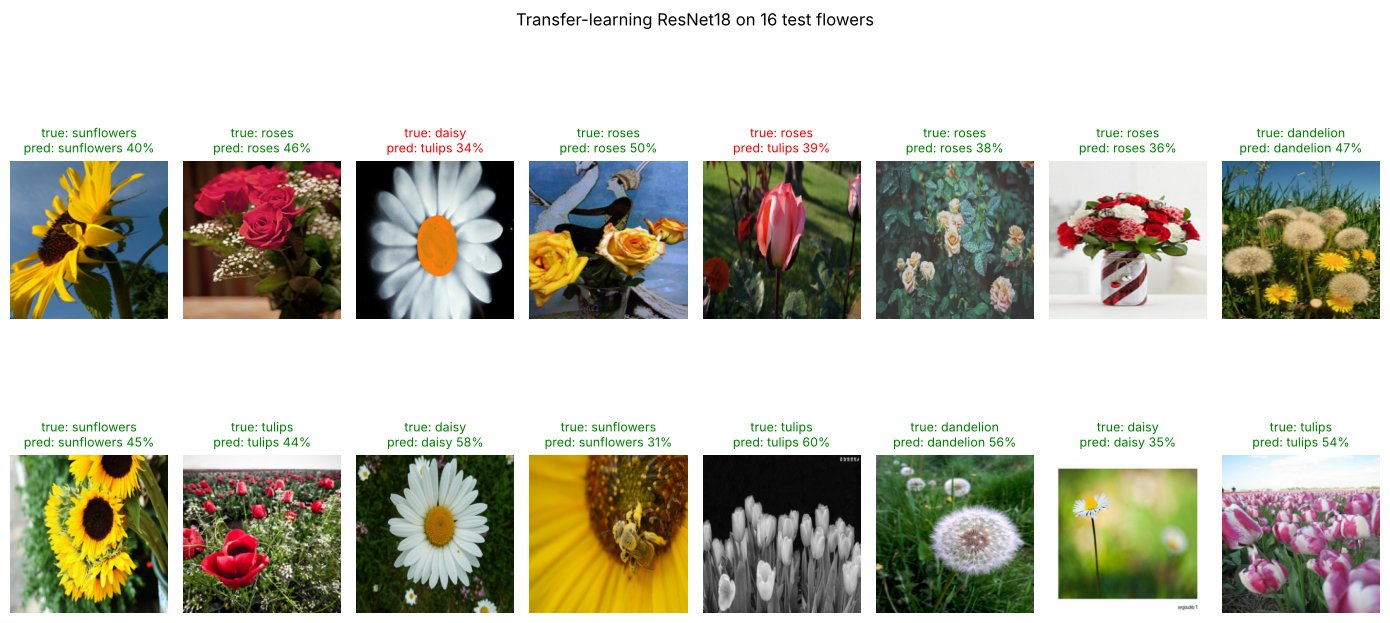

Predicted: sunflowers roses tulips roses


In [12]:
loader = torch.utils.data.DataLoader(testset, batch_size=16, shuffle=True, generator=torch.Generator().manual_seed(0))
images, labels = next(iter(loader))
resnet18.eval()
with torch.no_grad():
    probs = torch.softmax(resnet18(images.to(device)), 1).cpu()
conf, predicted = probs.max(1)
plt.figure(figsize=(14, 7.5))
for k in range(16):
    plt.subplot(2, 8, k + 1); imshow(images[k]); plt.axis("off")
    plt.title(f"true: {class_names[labels[k]]}\npred: {class_names[predicted[k]]} {conf[k]:.0%}", fontsize=9,
              color="green" if predicted[k] == labels[k] else "red")
plt.suptitle("Transfer-learning ResNet18 on 16 test flowers"); plt.tight_layout(); plt.show()
print('Predicted:', ' '.join(f'{class_names[predicted[j]]}' for j in range(4)))

### 3.4 Why does transfer learning work? Train the same ResNet18 from scratch

Same architecture, same 500 training photos, same transform, same 6 epochs, same Adam lr = 0.001. The only difference: **random weights** (`weights=None`) and **all** 11 million parameters trainable. The from-scratch model also has to compute gradients through the whole network, so each epoch is slower.

In [13]:
torch.manual_seed(0)
scratch = models.resnet18(weights=None, num_classes=len(class_names)).to(device)   # random weights, fc already 512 -> 5
opt_scratch = optim.Adam(scratch.parameters(), lr=0.001)
print(f"trainable parameters: {sum(p.numel() for p in scratch.parameters() if p.requires_grad):,}")
hist_sc = fit(scratch, opt_scratch, EPOCHS, "scratch")

trainable parameters: 11,179,077


[scratch] Epoch 1, Loss: 1.6889, test accuracy: 30.0%  (train time 139s)


[scratch] Epoch 2, Loss: 1.2848, test accuracy: 41.6%  (train time 144s)


[scratch] Epoch 3, Loss: 1.1813, test accuracy: 51.2%  (train time 143s)


[scratch] Epoch 4, Loss: 1.0748, test accuracy: 48.8%  (train time 143s)


[scratch] Epoch 5, Loss: 1.1280, test accuracy: 48.0%  (train time 63s)


[scratch] Epoch 6, Loss: 1.0823, test accuracy: 46.8%  (train time 59s)


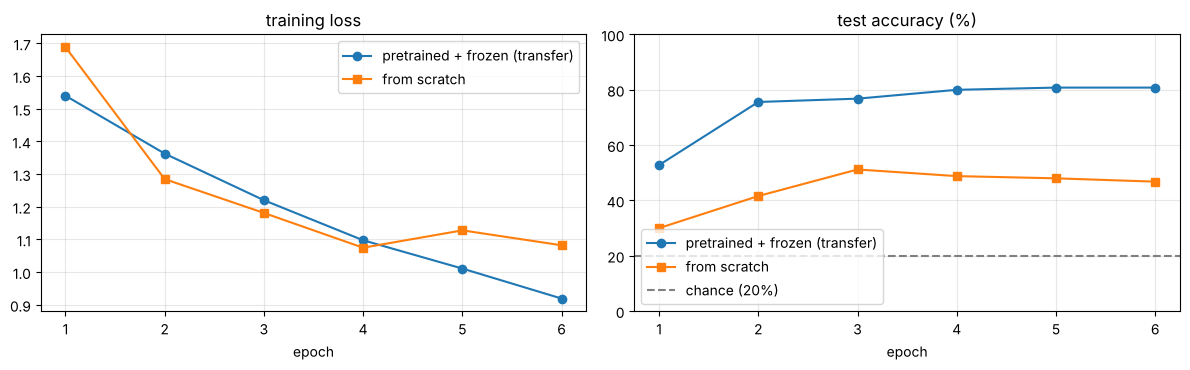

                                 test acc  trainable params  train s/epoch
ResNet18 pretrained + frozen        80.8%             2,565             52
ResNet18 from scratch               46.8%        11,179,077            115

per-class accuracy (from scratch):
  daisy        30.0%
  dandelion    54.0%
  roses        54.0%
  sunflowers   52.0%
  tulips       44.0%


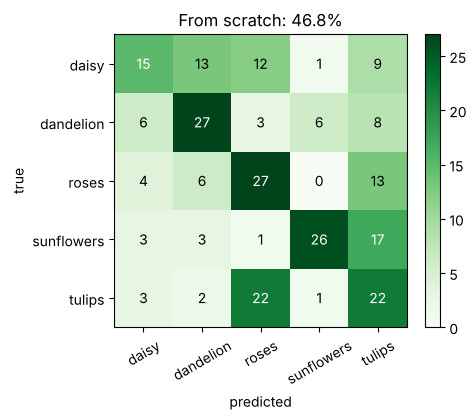

In [14]:
acc_sc, pred_sc, _ = evaluate(scratch, testloader)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ep = range(1, EPOCHS + 1)
ax[0].plot(ep, hist_tl["loss"], "o-", label="pretrained + frozen (transfer)")
ax[0].plot(ep, hist_sc["loss"], "s-", label="from scratch")
ax[0].set_title("training loss"); ax[0].set_xlabel("epoch"); ax[0].legend(); ax[0].grid(alpha=0.3)
ax[1].plot(ep, hist_tl["acc"], "o-", label="pretrained + frozen (transfer)")
ax[1].plot(ep, hist_sc["acc"], "s-", label="from scratch")
ax[1].axhline(100 / len(class_names), color="gray", ls="--", label="chance (20%)")
ax[1].set_title("test accuracy (%)"); ax[1].set_xlabel("epoch"); ax[1].set_ylim(0, 100); ax[1].legend(); ax[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

print(f"{'':32s}{'test acc':>9s}{'trainable params':>18s}{'train s/epoch':>15s}")
print(f"{'ResNet18 pretrained + frozen':32s}{acc_tl:8.1f}%{n_train:18,}{np.mean(hist_tl['time']):15.0f}")
print(f"{'ResNet18 from scratch':32s}{acc_sc:8.1f}%{sum(p.numel() for p in scratch.parameters()):18,}{np.mean(hist_sc['time']):15.0f}")
print("\nper-class accuracy (from scratch):")
per_class_and_confusion(pred_sc, true, f"From scratch: {acc_sc:.1f}%")

### 3.5 Use the classifier on a new photo

Save the trained model, load it back and classify a flower photo that was **in neither** our training nor our test subset (the full dataset has 3,670 photos and we used 750).

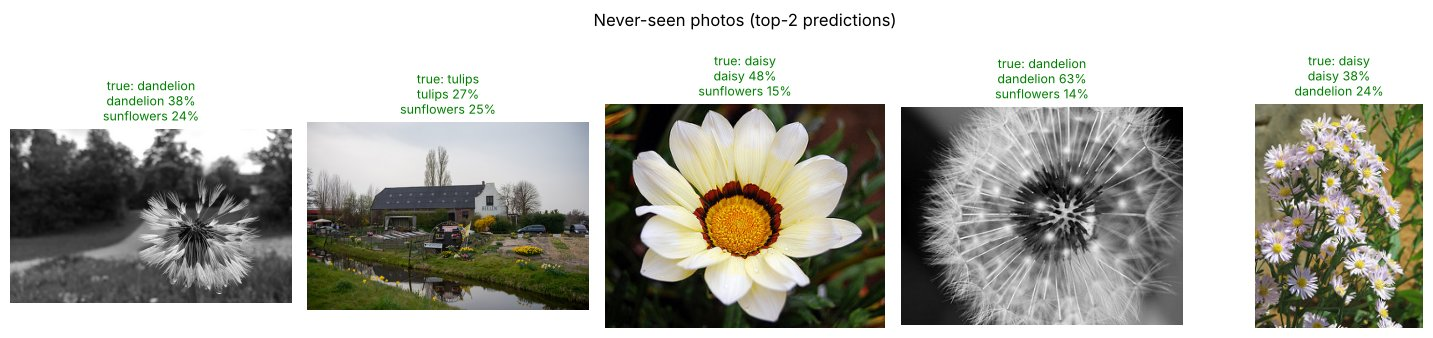

In [15]:
torch.save(resnet18.state_dict(), "data/resnet18_flowers.pt")
model = models.resnet18(weights=None)
model.fc = nn.Linear(512, len(class_names))
model.load_state_dict(torch.load("data/resnet18_flowers.pt", map_location="cpu"))
model.eval()

def predict_flower(path, model, k=3):
    x = transform(Image.open(path).convert("RGB")).unsqueeze(0)     # same transform as training, + batch dimension
    with torch.no_grad():
        p = torch.softmax(model(x), 1)[0]
    top = p.topk(k)
    return [(class_names[i], float(v)) for v, i in zip(top.values, top.indices)]

used = {f for split in ["train", "test"] for c in class_names for f in os.listdir(f"{data_dir}/{split}/{c}")}
unseen = [(c, f) for c in class_names for f in sorted(os.listdir(f"data/flower_photos/{c}")) if f not in used]
plt.figure(figsize=(15, 3.4))
for k, (c, f) in enumerate(random.Random(1).sample(unseen, 5)):
    path = f"data/flower_photos/{c}/{f}"
    res = predict_flower(path, model)
    plt.subplot(1, 5, k + 1); plt.imshow(Image.open(path)); plt.axis("off")
    plt.title(f"true: {c}\n" + "\n".join(f"{n} {p:.0%}" for n, p in res[:2]), fontsize=9, color="green" if res[0][0] == c else "red")
plt.suptitle("Never-seen photos (top-2 predictions)"); plt.tight_layout(); plt.show()

In [16]:
print(f"Total run time of this notebook: {(time.time() - NOTEBOOK_START) / 60:.1f} minutes")

Total run time of this notebook: 23.3 minutes


## 🔧 What we changed from the course notebook, and why

| Course code | Our version | Why |
|---|---|---|
| `data_dir = './custom_data'` (no data provided) | download TF *flower_photos*, build `data/custom_data/{train,test}/<class>/` with 100 + 50 photos per class | the course leaves the dataset to you; this is the standard layout for `ImageFolder` |
| `models.resnet18(pretrained=True)` | `weights=models.ResNet18_Weights.IMAGENET1K_V1`, with a **fallback** to timm's ImageNet ResNet18 weights from GitHub | `pretrained=` is deprecated; download.pytorch.org is blocked on the build machine (the output above shows which route ran) |
| comment "Freeze early layers" | comment corrected: the loop freezes **all** layers | only the new `fc` is trained |
| 2 epochs, prints the loss only | 6 epochs, test accuracy each epoch, time per epoch | to see the learning curve |
| test loop without `model.eval()` | `evaluate()` calls `model.eval()` | BatchNorm would use test-batch statistics (measured in 3.2) |
| `imshow`: `img / 2 + 0.5` | `img * std + mean` with the ImageNet values | the course's version shows over-contrasted, clipped colours (side-by-side above) |
| batch prediction without `torch.no_grad()` | wrapped in `no_grad()` + `eval()` | no gradient graph needed |
| 4 predicted labels | per-class accuracy, confusion matrix, 16-image grid with true/pred, unseen-photo demo | a fuller evaluation |
| (not in course) | same ResNet18 **from scratch** | shows *why* transfer learning is used |

## Results, honestly

Measured in the run above. 5 flower classes, **500 training and 250 test photos**, CPU only, 6 epochs each:

| Model | Test accuracy | Trainable parameters | Training time per epoch |
|---|---|---|---|
| ResNet18 **pretrained + frozen**, new `fc` (course exercise) | **80.8 %** | 2,565 | about 52 s |
| ResNet18 **from scratch** (same data, same epochs) | **46.8 %** | 11,179,077 | about 115 s |
| chance (guessing) | 20 % | | |

What this shows:
- **Transfer learning works with very little data.** Training only 2,565 numbers on top of frozen ImageNet features reached 80.8 % after 6 short epochs. Its training loss was still falling (0.9193 at epoch 6), so more epochs, data augmentation or unfreezing `layer4` would probably add a few more points.
- **From scratch, the same network learns much less** from 500 photos (46.8 %). Its test accuracy peaked at 51.2 % in epoch 3 and then stopped improving (it drifted down a little), while its training loss levelled off around 1.1. 11 million weights are far too many to learn good visual features from 500 images; with longer training such a model would mostly start memorising the training photos (overfitting).
- **Forgetting `model.eval()` is not a small detail:** the course's test loop (model left in training mode) scored **47.2 %** instead of 80.8 %, because BatchNorm normalised each class-sorted test batch with its own statistics. With shuffled batches the damage almost vanished (80.4 %), because a mixed batch has statistics close to the stored ones. So the result without `eval()` depends on how the test batches happen to be put together; `eval()` makes it independent of that.
- **"Frozen" BatchNorm still moves:** `requires_grad=False` did not stop `bn1.running_mean` from changing during training (largest change 5.3415).
- The model is right but **not very confident** (many top probabilities in the grid are 35–60 %). With 5 classes and a briefly trained head that's expected; longer training sharpens it.
- **Which route ran:** the official torchvision weights could not be downloaded here, so the notebook used timm's ImageNet ResNet18 weights from GitHub. On a normal connection you'll get the official weights, and slightly different numbers.
- **Timing:** this notebook was run on a CPU shared with other jobs, which made every epoch slower than on an idle machine. The *ratio* is what matters: the from-scratch epochs took about 2.2× as long, because gradients had to flow through the whole network.

## Common errors and how to fix them

| Error / symptom | Cause | Fix |
|---|---|---|
| `FileNotFoundError: Couldn't find any class folder in ./custom_data/train` | wrong path or wrong layout | `ImageFolder` needs `root/<class_name>/<image>`; check with `os.listdir(data_dir + '/train')` |
| test classes in a different order from train | different folder names in train/test | use **identical** class folder names in both; compare `trainset.classes` and `testset.classes` |
| `RuntimeError: ... size mismatch for fc.weight: copying a param with shape torch.Size([1000, 512]) ... torch.Size([5, 512])` | loading a 1000-class checkpoint into a 5-class model (or the other way round) | replace `fc` *after* loading the ImageNet weights, and *before* loading your own fine-tuned `.pt` |
| `mat1 and mat2 shapes cannot be multiplied (32x512 and 2048x5)` | wrong `in_features` (2048 is for ResNet50) | always use `model.fc.in_features` rather than typing the number |
| accuracy poor with a pretrained model | forgot the ImageNet `Normalize` (or used different values) | normalise with `[0.485,0.456,0.406]` / `[0.229,0.224,0.225]` |
| plotted images have strange, over-contrasted colours | un-normalised with `/2 + 0.5` after an ImageNet `Normalize` | un-normalise with `img * std + mean` |
| `Expected all tensors to be on the same device` | replaced `fc` **after** `model.to(device)`, so the new layer is on the CPU | call `.to(device)` after replacing `fc` (the course does this correctly) |
| `CUDA out of memory` | 224×224 images, batch too large | lower `batch_size` (32 → 16) |
| `URLError` downloading the weights | no access to download.pytorch.org | the notebook falls back to the GitHub copy automatically |
| `UserWarning: 'pretrained' is deprecated` | old API | `weights=models.ResNet18_Weights.DEFAULT` |

## Try this yourself

1. **Real fine-tuning.** After training `fc`, unfreeze the last stage: `for p in resnet18.layer4.parameters(): p.requires_grad = True`, then train again with `optim.Adam([{'params': resnet18.layer4.parameters(), 'lr': 1e-4}, {'params': resnet18.fc.parameters(), 'lr': 1e-3}])`. Does test accuracy rise? (Slower on a CPU.)
2. **Data augmentation.** Use `transforms.RandomResizedCrop(224)` + `transforms.RandomHorizontalFlip()` for the **training** transform only.
3. **Fewer images.** Set `N_TRAIN_PER_CLASS = 20`. How does transfer learning cope compared with training from scratch?
4. **EfficientNet.** Replace ResNet18 with `models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.DEFAULT)`. Its last layer is `model.classifier[1]` (`Linear(1280, 1000)`), so replace that instead of `fc`.
5. **Your own dataset.** Put photos in `data/custom_data/train/<class>/` and `data/custom_data/test/<class>/` (at least ~30 per class) and re-run from section 1's loader cell.
6. **Fully frozen BatchNorm.** Train with the BatchNorm layers in eval mode (see the tip in 2.2). Does accuracy change?

## Run it on Google Colab with a GPU

1. Upload the notebook to [colab.research.google.com](https://colab.research.google.com); **Runtime → Change runtime type → T4 GPU**.
2. Delete the `torch.set_num_threads(2)` line; `device` will print `cuda`.
3. Run all. The official weights download works there, so the output will say `WEIGHTS ROUTE: official`.
4. With a GPU you can afford `N_TRAIN_PER_CLASS = 500` and unfreezing `layer4` (Try this 1).

## Viva questions (with short model answers)

1. **What is transfer learning?** Reusing a model trained on a large dataset (ImageNet) as the starting point for a new task. Its general features (edges, textures, shapes) transfer, so we need little data and compute.
2. **What does `param.requires_grad = False` do?** It freezes the parameter: no gradient is computed for it, so the optimiser does not update it.
3. **Why replace `resnet18.fc`?** The original `fc` is `Linear(512, 1000)` for ImageNet's classes. We need one output per flower class, `Linear(512, 5)`. The new layer is trainable by default.
4. **Why pass only `resnet18.fc.parameters()` to the optimiser?** Only those are trainable. It also makes the intent explicit and avoids keeping optimiser state for frozen weights.
5. **Feature extraction vs fine-tuning?** Feature extraction = freeze the whole backbone and train only the new head (this lab). Fine-tuning = also unfreeze some or all pretrained layers and train them with a small learning rate.
6. **Why `Resize((224,224))` and ImageNet mean/std?** The network was pretrained on 224×224 images normalised with those statistics. Inputs must match what it saw during training.
7. **What folder structure does `ImageFolder` expect, and how are labels assigned?** `root/class_name/image.jpg`. Labels are the class folders in alphabetical order (`class_to_idx`).
8. **Why does the course's `imshow` show wrong colours?** It undoes a (0.5, 0.5) normalisation, but the data was normalised with the ImageNet mean/std, so values are stretched outside 0–1 and clipped. Correct: `img * std + mean` per channel.
9. **What is a residual connection and why does it help?** `out = F(x) + x`. The identity path lets gradients flow straight back (derivative has a "+1"), so very deep networks train without vanishing gradients.
10. **Why did the from-scratch ResNet18 do worse on the same data?** 11 M random weights cannot learn good visual features from 500 photos in 6 epochs (and would overfit with more). The pretrained one already has features learned from 1.28 M images, so only 2,565 weights need to be learned.
11. **Why is the transfer model faster per epoch?** No gradients are computed through the frozen backbone, only through the last layer. The forward pass is the same cost.
12. **Does `requires_grad=False` freeze BatchNorm completely?** No. The running mean/variance still update in `train()` mode (we measured this). Put the BatchNorm layers in `eval()` mode to freeze them fully.
13. **What happens if you test without `model.eval()`?** BatchNorm uses each test batch's own statistics (and dropout, if present, stays on), so results depend on which images share a batch. In 3.2: 80.8 % with `eval()`, 47.2 % without it on class-sorted batches, 80.4 % without it on shuffled batches.
14. **When would you *not* freeze the backbone?** When you have lots of data, or your images are very different from ImageNet (e.g. X-rays, satellite images). Then fine-tune more layers with a small learning rate.
15. **ResNet vs EfficientNet in one line each?** ResNet: skip connections make depth trainable. EfficientNet: compound scaling of depth, width and resolution together for the best accuracy per computation.